# Ensemble PINNs: uncertainty on an identified parameter

The inverse vessel PINN identifies the quadratic drag coefficient from noisy
coast-down data. A single run returns one number — but **how much should we
trust it?** The pragmatic answer is a *deep ensemble*: retrain the same
inverse problem $M$ times with different network initializations and
bootstrap-resampled noisy data, and read the spread of the identified
parameter.

Benchmark (1-DOF surge coast-down):
$$m\,\dot u = -d_1 u - d_2\,u|u|,\qquad u(0)=u_0,$$
with $m=10$, $d_1=1$ known and $d_2$ (=2 in truth) to be identified from
noisy samples of $u(t)$. It approximates what a fully Bayesian treatment
(a posterior over parameters) would give, at the cost of a for-loop — the
honest small-budget UQ.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0             # data draw; member seeds are MEMBER_SEED0, MEMBER_SEED0 + 1, ...
MEMBER_SEED0 = 1000
MASS, D1, D2_TRUE = 10.0, 1.0, 2.0   # model m u' = -d1 u - d2 u|u|
U0, T = 2.0, 8.0
N_OBS, SIGMA = 25, 0.03              # noisy measurements and their noise std
M = 8                                # ensemble members
STEPS, LR, W_DATA = 5000, 3e-3, 50.0
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, MEMBER_SEED0=1000, MASS=10.0, D1=1.0, D2_TRUE=2.0, U0=2.0, T=8.0,
                N_OBS=25, SIGMA=0.03, M=8, STEPS=5000, LR=3e-3, W_DATA=50.0)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import torch
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.pinn_core import MLP, grad, train
set_plot_style()
torch.set_default_dtype(torch.float64)
torch.manual_seed(SEED); np.random.seed(SEED)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## 1. Ground truth and noisy data

In [3]:
m_, d1, d2_true, u0 = MASS, D1, D2_TRUE, U0

def rhs(u):
    return -(d1*u + d2_true*u*np.abs(u))/m_

# fine RK4 reference
def rk4(f, u0, dt, n):
    us = [u0]
    u = u0
    for _ in range(n):
        k1 = f(u); k2 = f(u+dt/2*k1); k3 = f(u+dt/2*k2); k4 = f(u+dt*k3)
        u = u + dt/6*(k1+2*k2+2*k3+k4)
        us.append(u)
    return np.array(us)

dt_ref = 1e-3
u_ref = rk4(rhs, u0, dt_ref, int(T/dt_ref))
t_ref = np.linspace(0, T, len(u_ref))

# noisy measurements
n_obs, sigma = N_OBS, SIGMA
t_obs = np.sort(np.random.uniform(0, T, n_obs))
u_clean = np.interp(t_obs, t_ref, u_ref)
u_obs0 = u_clean + sigma*np.random.randn(n_obs)
print(f"{n_obs} observations, noise sigma = {sigma}")

25 observations, noise sigma = 0.03


## 2. One inverse-PINN member

Hard initial condition via $u_\theta(t)=u_0 + t\,N_\theta(t)$; the unknown
$d_2$ is one extra trainable scalar in the same Adam loop. Each ensemble
member gets (a) its own initialization and (b) a bootstrap resample of the
observations with fresh noise — capturing both sources of run-to-run
variability.

In [4]:
t_col = torch.linspace(0, T, 120).reshape(-1, 1).requires_grad_(True)

def fit_member(seed):
    g = torch.Generator().manual_seed(seed)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n_obs, n_obs)                     # bootstrap resample
    u_obs = u_clean[idx] + sigma*rng.standard_normal(n_obs) # fresh noise draw
    t_d = torch.tensor(t_obs[idx].reshape(-1, 1))
    u_d = torch.tensor(u_obs.reshape(-1, 1))

    net = MLP([1, 32, 32, 1])
    log_d2 = torch.tensor([0.0], requires_grad=True)        # d2 = exp(log_d2) > 0

    def u_hat(t):
        return u0 + t*net(t)

    def loss():
        u = u_hat(t_col)
        du = grad(u, t_col)
        d2 = torch.exp(log_d2)
        res = m_*du + d1*u + d2*u*torch.abs(u)
        l_data = ((u_hat(t_d) - u_d)**2).mean()
        return (res**2).mean() + W_DATA*l_data

    train(loss, list(net.parameters()) + [log_d2], steps=STEPS, lr=LR)
    with torch.no_grad():
        ts = torch.tensor(t_ref[::40].reshape(-1, 1))
        traj = u_hat(ts).numpy().ravel()
    return float(torch.exp(log_d2)), traj

## 3. Train the ensemble

In [5]:
d2_hats, trajs = [], []
for s in range(M):
    d2_s, traj_s = fit_member(MEMBER_SEED0 + s)
    d2_hats.append(d2_s); trajs.append(traj_s)
    print(f"member {s}: d2_hat = {d2_s:.4f}")
d2_hats = np.array(d2_hats); trajs = np.array(trajs)
mu, sd = d2_hats.mean(), d2_hats.std(ddof=1)
print(f"\nensemble: d2 = {mu:.3f} +/- {2*sd:.3f} (2 sigma), truth {d2_true}")
assert abs(mu - d2_true) < 4*sd + 0.15, "truth should lie near the ensemble mean"

/var/folders/px/kfx0kpc11td_5_f5ny95_wrh0000gn/T/ipykernel_74685/1000446061.py:30: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  return float(torch.exp(log_d2)), traj


member 0: d2_hat = 1.7426


member 1: d2_hat = 1.9935


member 2: d2_hat = 1.0433


member 3: d2_hat = 1.0116


member 4: d2_hat = 1.9411


member 5: d2_hat = 1.8455


member 6: d2_hat = 2.0241


member 7: d2_hat = 1.9694

ensemble: d2 = 1.696 +/- 0.845 (2 sigma), truth 2.0


## 4. Read the spread

The histogram is the poor-man's posterior over $d_2$; the trajectory band is
the corresponding predictive envelope. Two readings matter:

1. **Clusters reveal local minima.** Most members land near the truth, but a
   minority settle in a second basin around $d_2\approx 1$ — a run-of-the-mill
   single PINN landing there would report a confidently wrong value with no
   warning. The ensemble makes the multi-modality *visible*; this is its
   quiet superpower, beyond error bars.
2. **The band bounds variability, not bias.** If the model form were wrong
   (a missing drag term), every member would agree on the same wrong value —
   a narrow band around a biased answer. Ensembles cannot detect that;
   residual diagnostics and CoSTA (module 20) can.

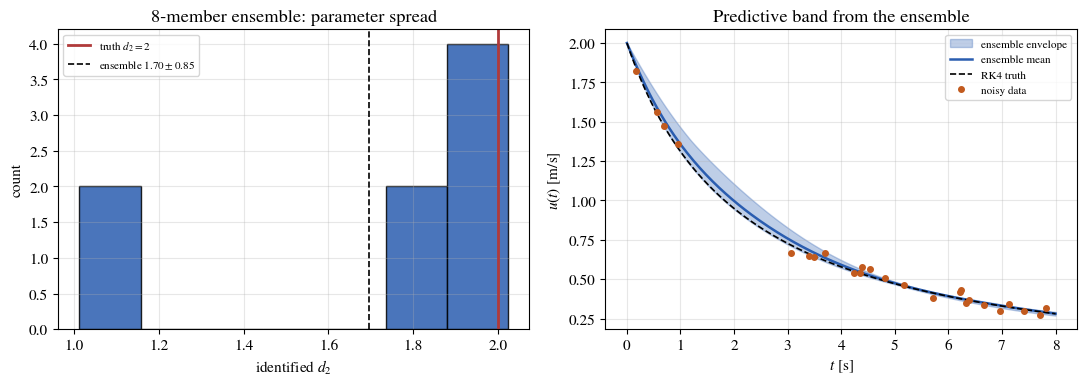

In [6]:
t_plot = t_ref[::40]

def plot_pinn_ensemble():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(d2_hats, bins=7, color='C0', alpha=0.85, edgecolor=fg())
    ax[0].axvline(d2_true, color='C3', lw=2, label=f'truth $d_2={d2_true:g}$')
    ax[0].axvline(mu, color=fg(), lw=1.2, ls='--',
                  label=f'ensemble ${mu:.2f}\\pm{2*sd:.2f}$')
    ax[0].set(xlabel='identified $d_2$', ylabel='count',
              title=f'{M}-member ensemble: parameter spread')
    ax[0].legend(fontsize=8)
    lo, hi = trajs.min(0), trajs.max(0)
    ax[1].fill_between(t_plot, lo, hi, color='C0', alpha=0.3,
                       label='ensemble envelope')
    ax[1].plot(t_plot, trajs.mean(0), color='C0', lw=1.8, label='ensemble mean')
    ax[1].plot(t_ref, u_ref, color=fg(), ls='--', lw=1.2, label='RK4 truth')
    ax[1].plot(t_obs, u_obs0, 'o', color='C1', ms=4, label='noisy data')
    ax[1].set(xlabel='$t$ [s]', ylabel='$u(t)$ [m/s]',
              title='Predictive band from the ensemble')
    ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_pinn_ensemble, 'pinn_ensemble', FIG)
plt.show()

## Summary

* A deep ensemble turns the inverse PINN into a cheap UQ device: retrain
  with fresh seeds + bootstrapped data, report mean ± spread — and inspect
  the histogram for clusters, which expose optimization multi-modality that
  any single run hides.
* It is the practical stand-in for a fully Bayesian PINN, which places a
  genuine posterior over the parameters at far higher cost.
* Read the band honestly: it reflects run-to-run variability under the
  stated noise model, not model-form error — CoSTA (module 20) is the tool
  when the *equations* are wrong, and the ensemble spread of $d_2$ here
  feeds directly into risk-aware decisions.

In [7]:
if AT_DEFAULTS:
    # numbers quoted on the slides and in notes/variants.tex
    assert abs(mu - 1.70) < 0.02 and abs(2*sd - 0.85) < 0.03, (mu, 2*sd)
    assert (d2_hats < 1.2).sum() == 2, "two members land in the second basin near d2 = 1"
    print(f'slide numbers: d2 = {mu:.2f} +/- {2*sd:.2f}; members near 1: {(d2_hats < 1.2).sum()}')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

slide numbers: d2 = 1.70 +/- 0.85; members near 1: 2
